# PyTorch Setup
- CUDA
    - torch.cuda for CUDA ops
    - special tensor types e.g. torch.cuda.FloatTensor
    - torch.cuda.device('cuda') to select GPU
    - asynchronous execution
        - allows parallel processing
        - FIFO
        - not perceptible to user

# Linear Regression
- objective: finding a straight line that fits the data and can make predictions
    - Objective function: minimize LSE
    - constraints: express relationship as a straight line
    - decision variables: values for w & b, weights and biases
- prevent overfitting via regularization
    - l2 regularization of coefficients
    - hads regularization term as a penalty to avoid overfitting
    - alpha = strength of regularization
        - higher -> stronger penalty

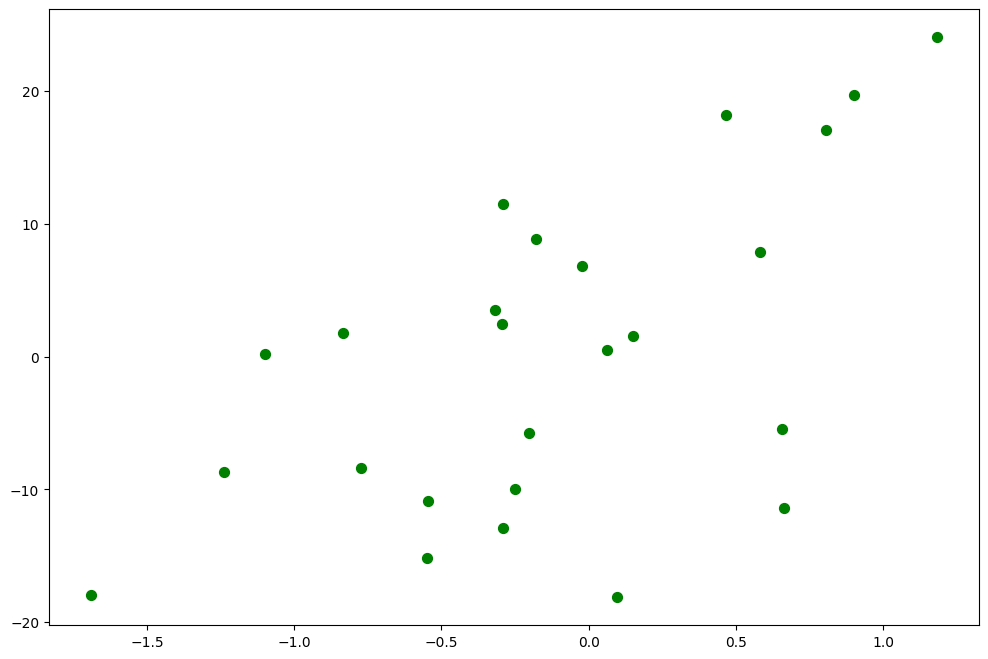

In [153]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression

x, y = make_regression(25, 1, noise=10)
plt.figure(figsize=(12,8))
plt.scatter(x, y, c='green', s=50, label='OG data')
plt.show()



In [135]:
import torch

x_train = torch.from_numpy(x).float()
y_train = torch.from_numpy(y).float().view(-1,1)

print('x requires grad:', x_train.requires_grad)
print('y requires grad:', y_train.requires_grad)

x requires grad: False
y requires grad: False


In [136]:
input_size = 1
hidden_size = 10
output_size = 1
learning_rate = 0.001
alpha = 0.8

w1 = torch.rand(input_size, hidden_size, requires_grad=True)
w2 = torch.rand(hidden_size, output_size, requires_grad=True)
b1 = torch.rand(1, hidden_size, requires_grad=True)
b2 = torch.rand(1, output_size, requires_grad=True)
w1.shape, w2.shape, b1.shape, b2.shape

(torch.Size([1, 10]),
 torch.Size([10, 1]),
 torch.Size([1, 10]),
 torch.Size([1, 1]))

In [137]:
class LinReg:
    def __init__(self, w1, w2, b1, b2):
        self.w1 = w1
        self.w2 = w2
        self.b1 = b1
        self.b2 = b2
    
    def forward(self, x):
        y1 = torch.matmul(x, self.w1) + self.b1
        y2 = torch.matmul(y1, self.w2) + self.b2
        return y2
    
model = LinReg(w1, w2, b1, b2)

In [138]:
for i in range(1, 10001):
    # forward pass
    y_pred = model.forward(x_train)

    ridge_reg_penalty = torch.sum(w1**2)

    # calc loss
    loss = torch.mean((y_pred-y_train)**2) + (alpha*ridge_reg_penalty)

    if i % 100 == 0:
        print(i, loss.item())
    # backward pass
    loss.backward()

    # update weights
    with torch.no_grad():
        model.w1 -= learning_rate * model.w1.grad
        model.w2 -= learning_rate * model.w2.grad
        model.b1 -= learning_rate * model.b1.grad
        model.b2 -= learning_rate * model.b2.grad
            # Zero out gradients after each epoch
        model.w1.grad.zero_()
        model.w2.grad.zero_()
        model.b1.grad.zero_()
        model.b2.grad.zero_()

100 121.34384155273438
200 117.61918640136719
300 114.79740142822266
400 112.60198211669922
500 110.85194396972656
600 109.42662811279297
700 108.24383544921875
800 107.24623107910156
900 106.39295196533203
1000 105.6540756225586
1100 105.00743103027344
1200 104.4361801147461
1300 103.92739868164062
1400 103.47089385986328
1500 103.05864715576172
1600 102.68418884277344
1700 102.3423080444336
1800 102.02864837646484
1900 101.73967742919922
2000 101.47242736816406
2100 101.22434997558594
2200 100.99334716796875
2300 100.777587890625
2400 100.57550048828125
2500 100.38574981689453
2600 100.20716094970703
2700 100.0386962890625
2800 99.87945556640625
2900 99.72868347167969
3000 99.5855712890625
3100 99.44963836669922
3200 99.32020568847656
3300 99.19681549072266
3400 99.07905578613281
3500 98.96648406982422
3600 98.8587417602539
3700 98.75550079345703
3800 98.65646362304688
3900 98.56136322021484
4000 98.46994018554688
4100 98.38195037841797
4200 98.2972183227539
4300 98.21556091308594
44

In [139]:
print('w1:', w1)
print('w2:', w2)
print('b1:', b1)
print('b2:', b2)

w1: tensor([[0.8136, 1.1435, 1.1159, 0.9735, 0.3955, 0.1425, 0.5324, 0.3858, 0.4772,
         0.4863]], requires_grad=True)
w2: tensor([[6.3264],
        [8.8912],
        [8.6766],
        [7.5693],
        [3.0756],
        [1.1083],
        [4.1395],
        [3.0000],
        [3.7102],
        [3.7811]], requires_grad=True)
b1: tensor([[-0.0737, -0.5741,  0.1209, -0.1185,  0.4567,  0.8182,  0.0480, -0.0111,
         -0.3737,  0.4393]], requires_grad=True)
b2: tensor([[0.0287]], requires_grad=True)


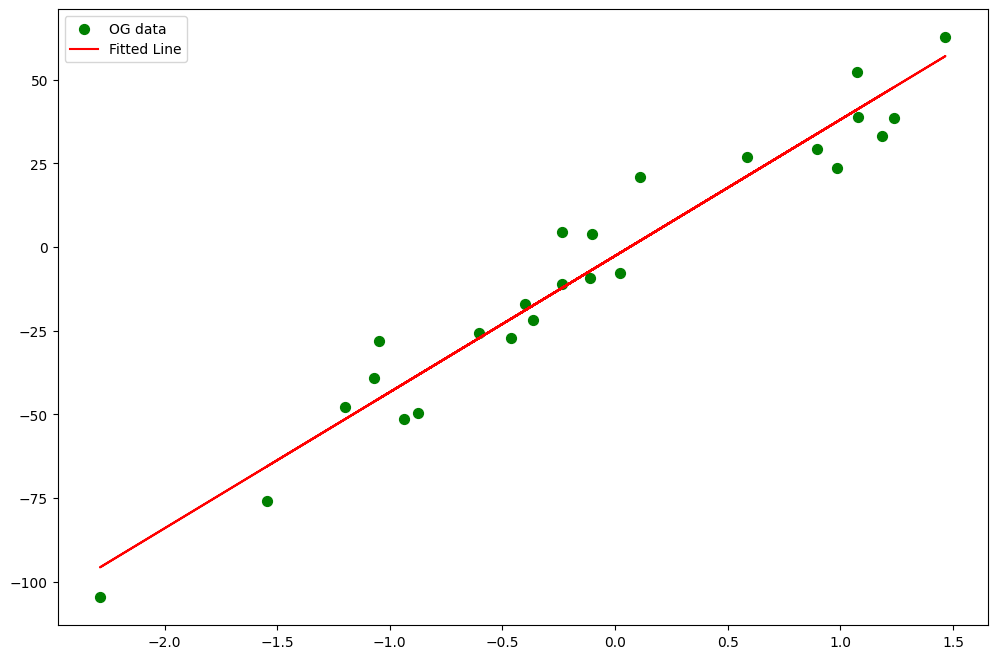

In [140]:
plt.figure(figsize=(12,8))
plt.scatter(x, y, c='green', s=50, label='OG data')
plt.plot(x_train.detach().numpy(), y_pred.detach().numpy(), label='Fitted Line', color='red')
plt.legend()
plt.show()

In [141]:
model.w1, model.w2, model.b1, model.b2

(tensor([[0.8136, 1.1435, 1.1159, 0.9735, 0.3955, 0.1425, 0.5324, 0.3858, 0.4772,
          0.4863]], requires_grad=True),
 tensor([[6.3264],
         [8.8912],
         [8.6766],
         [7.5693],
         [3.0756],
         [1.1083],
         [4.1395],
         [3.0000],
         [3.7102],
         [3.7811]], requires_grad=True),
 tensor([[-0.0737, -0.5741,  0.1209, -0.1185,  0.4567,  0.8182,  0.0480, -0.0111,
          -0.3737,  0.4393]], requires_grad=True),
 tensor([[0.0287]], requires_grad=True))

# Building Regression Model
- optimizers:
    - torch.optim.Optimizer
    - .Adadealta
    - .Adagrad
    - .Adam -> adaptive moment estimation
- gradient optimizer
    - torch.optim.SGD
        - pass model.parameters(), lr=
        - .step() -> updating model parameters after each epoch
    - momentum-based optimizer: 
        - momentum_vec = momentum_coeff + learning_rate*g(theta)
        - p(t+1) = p(t) - momentum_vec
- torch.nn.Sequential()
    - sequential container for neural network layers
    - layers are applied to inputs in order
- torch.nn.Linear()
    - linear layer
    - class object
    - 2 parameters: size of the inputs
- torch.nn.MSELoss()
    - (reduction='sum') -> returns the sum of SE

In [155]:
x, y = make_regression(25, 1, noise=10)

x_train = torch.from_numpy(x).float()
y_train = torch.from_numpy(y).float().view(-1,1)

input_size = 1
hidden_size = 10
output_size = 1
learning_rate = 1e-4
alpha = 0.8

model = torch.nn.Sequential(
    torch.nn.Linear(input_size, hidden_size),
    torch.nn.Linear(hidden_size, output_size)
)

loss_fn = torch.nn.MSELoss(reduction='sum')

In [156]:
# manual param updates
for i in range(500):
    y_pred = model(x_train)
    loss = loss_fn(y_pred, y_train)
    print(i, loss.item())

    model.zero_grad()
    loss.backward()

    with torch.no_grad():
        for param in model.parameters():
            param -= learning_rate * param.grad

0 103768.3359375
1 101988.9765625
2 99837.125
3 96917.8828125
4 92785.421875
5 86932.53125
6 78852.015625
7 68217.1796875
8 55205.6484375
9 40855.4453125
10 27094.9140625
11 16040.251953125
12 8814.060546875
13 5008.73828125
14 3367.429443359375
15 2764.175048828125
16 2565.77685546875
17 2504.774169921875
18 2486.66748046875
19 2481.37158203125
20 2479.826171875
21 2479.37353515625
22 2479.23974609375
23 2479.199462890625
24 2479.187744140625
25 2479.18408203125
26 2479.182861328125
27 2479.18212890625
28 2479.1826171875
29 2479.18310546875
30 2479.18212890625
31 2479.182373046875
32 2479.18212890625
33 2479.182373046875
34 2479.18212890625
35 2479.181884765625
36 2479.1826171875
37 2479.1826171875
38 2479.181884765625
39 2479.18212890625
40 2479.1826171875
41 2479.1826171875
42 2479.1826171875
43 2479.1826171875
44 2479.1826171875
45 2479.1826171875
46 2479.1826171875
47 2479.1826171875
48 2479.1826171875
49 2479.1826171875
50 2479.1826171875
51 2479.1826171875
52 2479.1826171875
53 

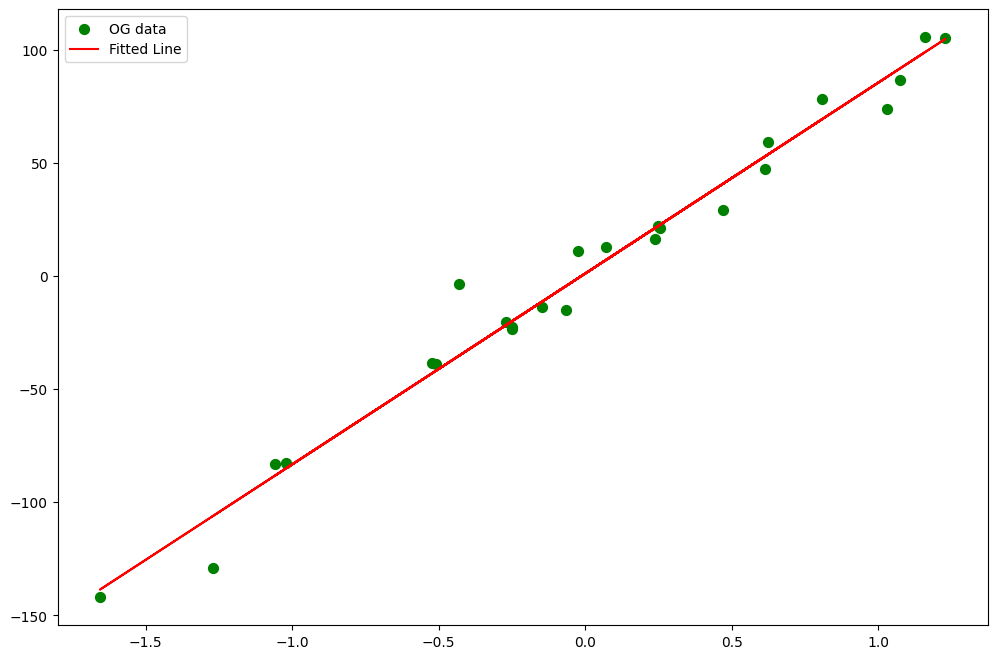

In [157]:
plt.figure(figsize=(12,8))
plt.scatter(x, y, c='green', s=50, label='OG data')
plt.plot(x_train.detach().numpy(), y_pred.detach().numpy(), label='Fitted Line', color='red')
plt.legend()
plt.show()

In [158]:
# auto param updates using optimizer
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

for i in range(500):
    y_pred = model(x_train)
    loss = loss_fn(y_pred, y_train)
    print(i, loss.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

0 2479.1826171875
1 2479.1826171875
2 2479.1826171875
3 2479.1826171875
4 2479.1826171875
5 2479.1826171875
6 2479.1826171875
7 2479.1826171875
8 2479.1826171875
9 2479.1826171875
10 2479.1826171875
11 2479.1826171875
12 2479.1826171875
13 2479.1826171875
14 2479.1826171875
15 2479.1826171875
16 2479.1826171875
17 2479.1826171875
18 2479.1826171875
19 2479.1826171875
20 2479.1826171875
21 2479.1826171875
22 2479.1826171875
23 2479.1826171875
24 2479.1826171875
25 2479.1826171875
26 2479.1826171875
27 2479.1826171875
28 2479.1826171875
29 2479.1826171875
30 2479.1826171875
31 2479.1826171875
32 2479.1826171875
33 2479.1826171875
34 2479.1826171875
35 2479.1826171875
36 2479.1826171875
37 2479.1826171875
38 2479.1826171875
39 2479.1826171875
40 2479.1826171875
41 2479.1826171875
42 2479.1826171875
43 2479.1826171875
44 2479.1826171875
45 2479.1826171875
46 2479.1826171875
47 2479.1826171875
48 2479.1826171875
49 2479.1826171875
50 2479.1826171875
51 2479.1826171875
52 2479.1826171875
53 

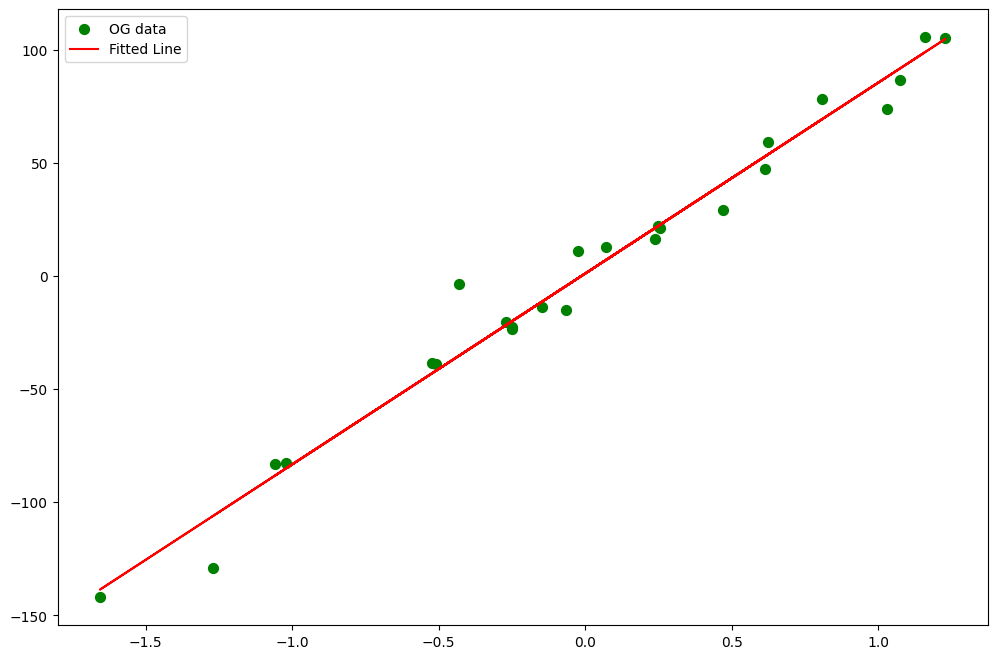

In [159]:
plt.figure(figsize=(12,8))
plt.scatter(x, y, c='green', s=50, label='OG data')
plt.plot(x_train.detach().numpy(), y_pred.detach().numpy(), label='Fitted Line', color='red')
plt.legend()
plt.show()

# Dropout
- technique to avoid overfitting
- dense all to all connections results in high risk of overfitting
- specify a fraction of neurons that will be excluded from each training step
    - selected at random
    - different neurons dropped for each step
    - each training step builds a different network
    - only dropped out during training
        - full dense nn will be implemented

# Epoch & Batch size
- epoch = 1 pass through the entire training data
    - broken down by multiple iteration of batches
- batch size is a design parameter
    - e.g., semi-batch / batch gradient descent

# Bike Sharing Demo
- Steps:
    1. data cleaning, e.g., text encoding
    2. split train and test data
    3. transform features and target from array to tensor, e.g., torch.tensor(array.values, dtype=tensor.float)
        - for target, ensure 2D structure using method chain: .view(-1, 1)
    4. batch training data:
        - import torch.utils.data as data_utils
        - create tensor dataset: training_data = data_utils.TensorDataset(X_train_ts, y_train_ts)
        - initialize data loader: train_loader = data_utils.DataLoader(training_data, batch_size=100, shuffle=True)
            - used for batching
    5. initialize model architecture:
        - input, hidden and output layer counts
            - input_size: number of input features, e.g., x_train_ts.shape[1]
            - output size: number of unique output values, e.g., len(y_train_ts.unique())
            - hidden: design-driven, proportional to model complexity 
        - loss function
        - learning rate
        - model: torch.nn.Sequential()
            - specifiy: torch.nn.Linear(inp, hid),
                        torch.nn.ReLU(),
                        torch.nn.Dropout(p=0.2)
        - optimizer: torch.optim.Adam(model.parameters(), lr=0.001)
            - model.parameters()
            - lr=    
    6. training
        - iterate over: 
            - total_step = len(train_loader)
            - num_epochs = 10000  
        - generate: output = model(features)
        - calc loss = loss_fn(output, target)
        - zero out grad: optimizer.zero_grad()
        - calculate gradient: loss.backward()
        - update model parameters: optimizer.step()
    7. prediction
        - must enable model.eval() before predictions
            - otherwise still using training setup, e.g. dropouts
        - with torch.no_grad(): turns off gradient calculations / compute graph to save memory
        - make prediction: y_pred_ts = model(X_test_ts)
    8. evaluation
        - calculate metric, e.g., sklearn.metrics.r2_score(y_test, y_pred)

In [1]:
import torch
import hiddenlayer as hl
import pandas as pd
import numpy as np
import seaborn as sns
import sklearn

In [ ]:
df_bike = pd.read_csv(r"C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\2 Building Model with PyTorch\02\demos\code\datasets\bike_sharing.csv",
                      index_col=0)
df_bike.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000000,211.165812,1.000000,183.500000,366.000000,548.500000,731.000000
yr,731.0,0.500684,0.500342,0.000000,0.000000,1.000000,1.000000,1.000000
mnth,731.0,6.519836,3.451913,1.000000,4.000000,7.000000,10.000000,12.000000
holiday,731.0,0.028728,0.167155,0.000000,0.000000,0.000000,0.000000,1.000000
weekday,731.0,2.997264,2.004787,0.000000,1.000000,3.000000,5.000000,6.000000
workingday,731.0,0.683995,0.465233,0.000000,0.000000,1.000000,1.000000,1.000000
weathersit,731.0,1.395349,0.544894,1.000000,1.000000,1.000000,2.000000,3.000000
temp,731.0,0.495385,0.183051,0.059130,0.337083,0.498333,0.655417,0.861667
atemp,731.0,0.474354,0.162961,0.079070,0.337842,0.486733,0.608602,0.840896
hum,731.0,0.627894,0.142429,0.000000,0.520000,0.626667,0.730209,0.972500


In [171]:
df_bike.shape

(731, 16)

In [172]:
df_bike = pd.get_dummies(df_bike, columns=['season'])
df_bike.shape

(731, 19)

In [180]:
target = df_bike['cnt']
features = df_bike.drop(columns=['instant', 'yr', 'mnth', 'cnt', 'dteday', 'hum', 'windspeed', 'casual'])
bool_columns = features.select_dtypes(include='bool').columns
features[bool_columns] = features[bool_columns].astype(int)
features.info()

<class 'pandas.core.frame.DataFrame'>
Index: 731 entries, 0 to 730
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   holiday        731 non-null    int64  
 1   weekday        731 non-null    int64  
 2   workingday     731 non-null    int64  
 3   weathersit     731 non-null    int64  
 4   temp           731 non-null    float64
 5   atemp          731 non-null    float64
 6   registered     731 non-null    int64  
 7   season_fall    731 non-null    int64  
 8   season_spring  731 non-null    int64  
 9   season_summer  731 non-null    int64  
 10  season_winter  731 non-null    int64  
dtypes: float64(2), int64(9)
memory usage: 68.5 KB


In [182]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2)

X_train_ts = torch.tensor(X_train.values, dtype=torch.float)
X_test_ts = torch.tensor(X_test.values, dtype=torch.float)
y_train_ts = torch.tensor(y_train.values, dtype=torch.float).view(-1, 1)
y_test_ts = torch.tensor(y_test.values, dtype=torch.float).view(-1, 1)

X_train_ts.shape, y_train_ts.shape

(torch.Size([584, 11]), torch.Size([584, 1]))

In [183]:
import torch.utils.data as data_utils

training_data = data_utils.TensorDataset(X_train_ts, y_train_ts)
train_loader = data_utils.DataLoader(training_data, batch_size=100, shuffle=True)
len(train_loader)

6

In [186]:
features_batch, target_batch = next(iter(train_loader))
features_batch.shape, target_batch.shape

(torch.Size([100, 11]), torch.Size([100, 1]))

In [188]:
inp = X_train_ts.shape[1]
out = 1
hid = 10
loss_fn = torch.nn.MSELoss()

model = torch.nn.Sequential(torch.nn.Linear(inp, hid),
                            torch.nn.Linear(hid, out))

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

total_step = len(train_loader)
num_epochs = 10000

for epoch in range(num_epochs+1):
    for i, (features, target) in enumerate(train_loader):
        output = model(features)
        loss = loss_fn(output, target)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 2000 ==0:
            print('Epoch [{}/{}], Step [{}/{}], Loss: {:.4f}'
                  .format(epoch+1, num_epochs, i+1, total_step, loss.item()))

Epoch [1/10000], Step [1/6], Loss: 22860836.0000
Epoch [1/10000], Step [2/6], Loss: 20476912.0000
Epoch [1/10000], Step [3/6], Loss: 19620664.0000
Epoch [1/10000], Step [4/6], Loss: 18086308.0000
Epoch [1/10000], Step [5/6], Loss: 19453830.0000
Epoch [1/10000], Step [6/6], Loss: 22314012.0000
Epoch [2001/10000], Step [1/6], Loss: 374282.3125
Epoch [2001/10000], Step [2/6], Loss: 332894.1875
Epoch [2001/10000], Step [3/6], Loss: 423673.4375
Epoch [2001/10000], Step [4/6], Loss: 512139.4375
Epoch [2001/10000], Step [5/6], Loss: 239933.5625
Epoch [2001/10000], Step [6/6], Loss: 251380.6406
Epoch [4001/10000], Step [1/6], Loss: 216541.1406
Epoch [4001/10000], Step [2/6], Loss: 215784.2344
Epoch [4001/10000], Step [3/6], Loss: 143609.3438
Epoch [4001/10000], Step [4/6], Loss: 233516.6250
Epoch [4001/10000], Step [5/6], Loss: 226777.5938
Epoch [4001/10000], Step [6/6], Loss: 180866.1250
Epoch [6001/10000], Step [1/6], Loss: 203114.9531
Epoch [6001/10000], Step [2/6], Loss: 117082.1172
Epoch 

In [193]:
model.eval()

with torch.no_grad():
    y_pred_ts = model(X_test_ts)

In [194]:
y_pred = y_pred_ts.detach().numpy()
y_pred.shape

(147, 1)

In [195]:
sklearn.metrics.r2_score(y_test, y_pred)

0.9569937586784363

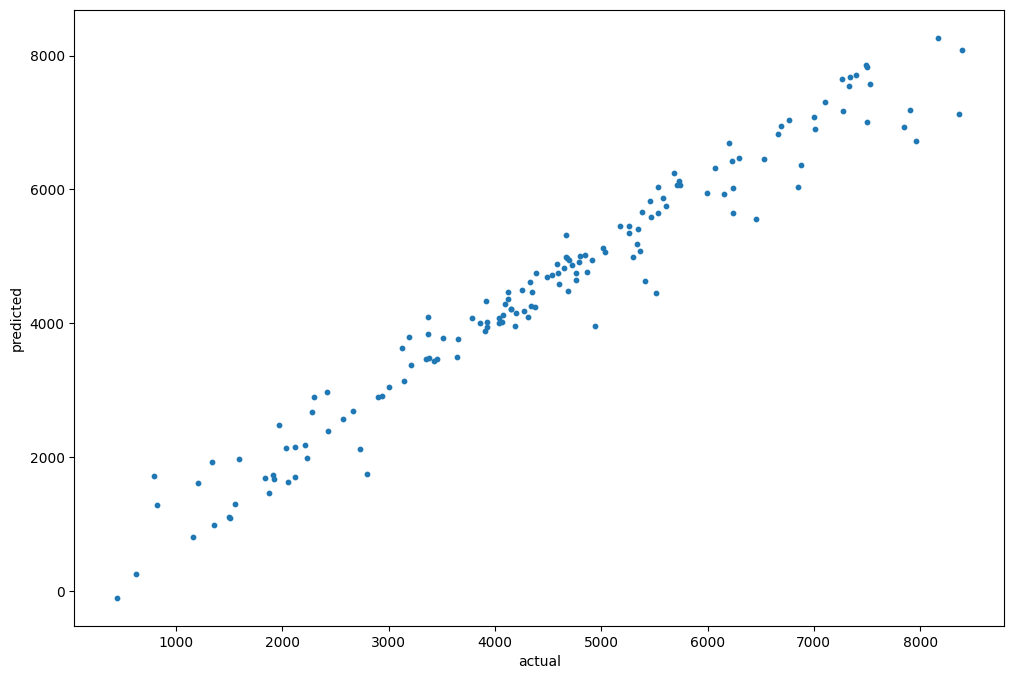

In [197]:
plt.figure(figsize=(12,8))
plt.scatter(y_test, y_pred, s=10)
plt.xlabel('actual')
plt.ylabel('predicted')
plt.show()

In [199]:
# Model 2 w/ ReLU & dropout
model2 = torch.nn.Sequential(torch.nn.Linear(inp, hid),
                             torch.nn.ReLU(),
                             torch.nn.Dropout(p=0.2),
                            torch.nn.Linear(hid, out))

for epoch in range(num_epochs+1):
    for i, (features, target) in enumerate(train_loader):
        output = model2(features)
        loss = loss_fn(output, target)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 2000 ==0:
            print('Epoch [{}/{}], Step [{}/{}], Loss: {:.4f}'
                  .format(epoch+1, num_epochs, i+1, total_step, loss.item()))

Epoch [1/10000], Step [1/6], Loss: 26040638.0000
Epoch [1/10000], Step [2/6], Loss: 25202406.0000
Epoch [1/10000], Step [3/6], Loss: 25090424.0000
Epoch [1/10000], Step [4/6], Loss: 23985008.0000
Epoch [1/10000], Step [5/6], Loss: 25687496.0000
Epoch [1/10000], Step [6/6], Loss: 25328822.0000
Epoch [2001/10000], Step [1/6], Loss: 23242642.0000
Epoch [2001/10000], Step [2/6], Loss: 26246364.0000
Epoch [2001/10000], Step [3/6], Loss: 25825382.0000
Epoch [2001/10000], Step [4/6], Loss: 26737256.0000
Epoch [2001/10000], Step [5/6], Loss: 24533708.0000
Epoch [2001/10000], Step [6/6], Loss: 24635700.0000
Epoch [4001/10000], Step [1/6], Loss: 22254400.0000
Epoch [4001/10000], Step [2/6], Loss: 25402594.0000
Epoch [4001/10000], Step [3/6], Loss: 26384600.0000
Epoch [4001/10000], Step [4/6], Loss: 24697416.0000
Epoch [4001/10000], Step [5/6], Loss: 24421126.0000
Epoch [4001/10000], Step [6/6], Loss: 26921034.0000
Epoch [6001/10000], Step [1/6], Loss: 27426576.0000
Epoch [6001/10000], Step [2/6]

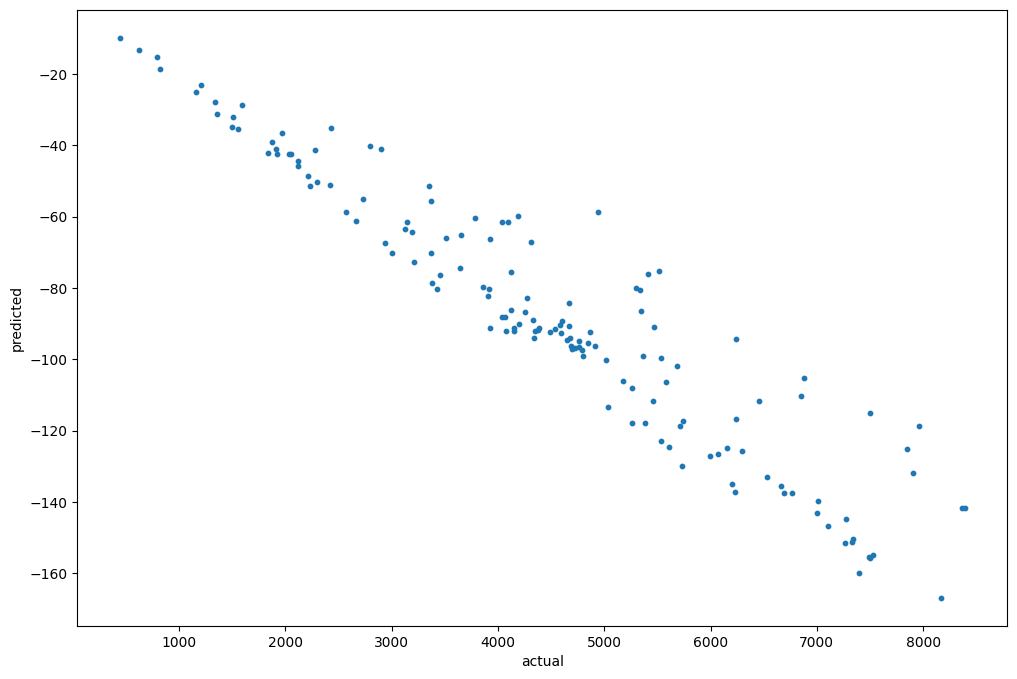

In [200]:
model2.eval()

with torch.no_grad():
    y_pred_ts = model2(X_test_ts)

y_pred = y_pred_ts.detach().numpy()

sklearn.metrics.r2_score(y_test, y_pred)

plt.figure(figsize=(12,8))
plt.scatter(y_test, y_pred, s=10)
plt.xlabel('actual')
plt.ylabel('predicted')
plt.show()

# Building Classification Model
- classification model: used to predict discrete / categorical values
- activation function: 
    - softmax function or log softmax
    - convert z value to a probability score
    - selects the highest p as the output category
    - similar to sigmoid except used for multi-class classifications
- loss function: 
    - cross entropy for softmax
    - negative log likelihood (nll) for log softmax
- objective function: minmize cross-entropy between y_act and y_pred
- constrain: express relationship as exponential
- decision variables: optimal parameters

In [2]:
df_adm = pd.read_csv(r"C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\2 Building Model with PyTorch\02\demos\code\datasets\graduate-admissions\admission_predict.csv",
                     )
df_adm.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Serial No.,400.0,200.500000,115.614301,1.00,100.75,200.50,300.2500,400.00
GRE Score,400.0,316.807500,11.473646,290.00,308.00,317.00,325.0000,340.00
TOEFL Score,400.0,107.410000,6.069514,92.00,103.00,107.00,112.0000,120.00
University Rating,400.0,3.087500,1.143728,1.00,2.00,3.00,4.0000,5.00
SOP,400.0,3.400000,1.006869,1.00,2.50,3.50,4.0000,5.00
LOR,400.0,3.452500,0.898478,1.00,3.00,3.50,4.0000,5.00
CGPA,400.0,8.598925,0.596317,6.80,8.17,8.61,9.0625,9.92
Research,400.0,0.547500,0.498362,0.00,0.00,1.00,1.0000,1.00
Chance of Admit,400.0,0.724350,0.142609,0.34,0.64,0.73,0.8300,0.97


In [3]:
df_adm = df_adm.rename(index=str, columns={'Chance of Admit ': 'Admi_Probability'})
features = df_adm.drop(columns=['Serial No.', 'Admi_Probability'])
target = df_adm['Admi_Probability']

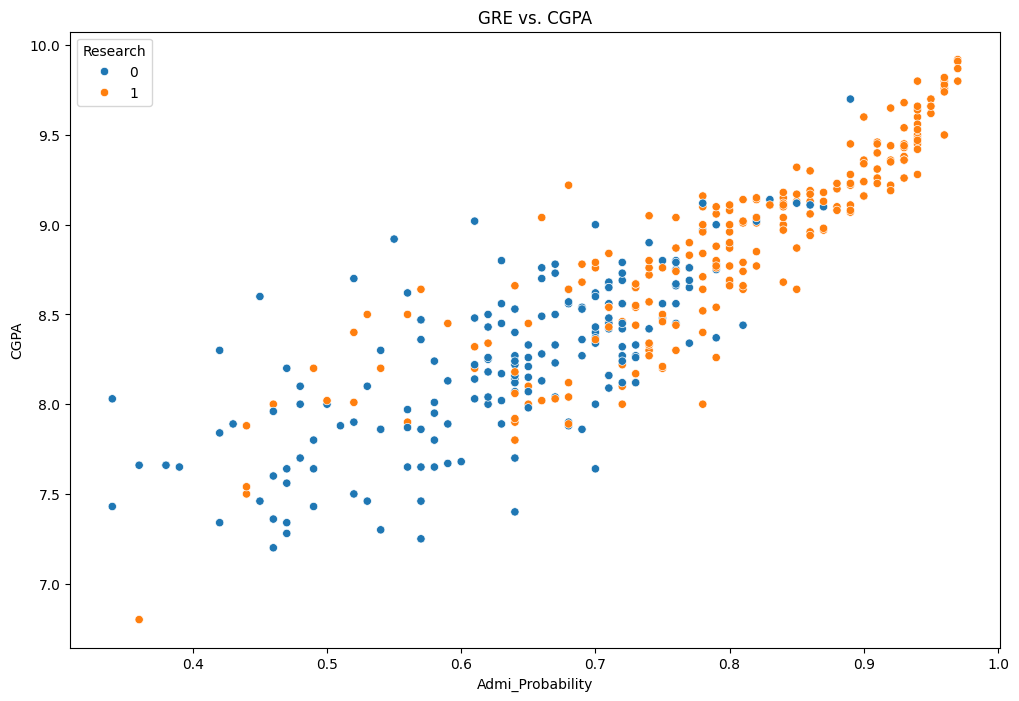

In [4]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,8))
sns.scatterplot(x='Admi_Probability', y='CGPA', data=df_adm, hue='Research')
plt.title('GRE vs. CGPA')
plt.show()

<Axes: >

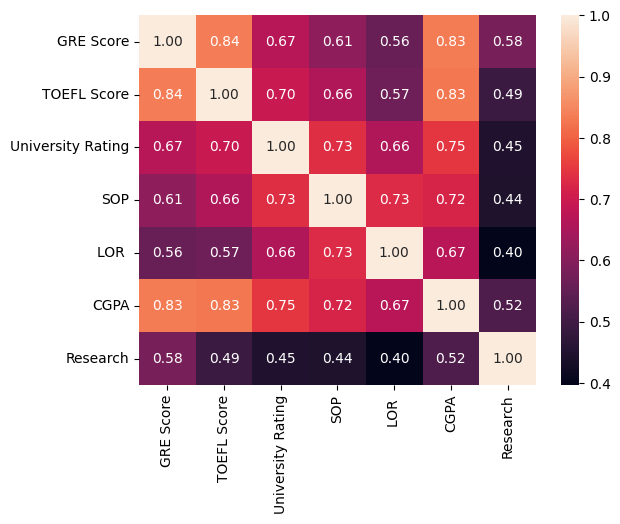

In [5]:
sns.heatmap(features.corr(), annot=True, fmt='.2f')

In [6]:
# preprocessing
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled_columns = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR ', 'CGPA']
features[scaled_columns] = scaler.fit_transform(features[scaled_columns], scaled_columns)
features.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
GRE Score,400.0,-4.174439e-16,1.001252,-2.339367,-0.768590,0.016799,0.714922,2.023903
TOEFL Score,400.0,5.595524e-16,1.001252,-2.542098,-0.727492,-0.067635,0.757186,2.076899
University Rating,400.0,7.105427e-17,1.001252,-1.827457,-0.952029,-0.076600,0.798829,1.674257
SOP,400.0,7.993606e-17,1.001252,-2.386613,-0.894980,0.099442,0.596653,1.591075
LOR,400.0,-1.332268e-16,1.001252,-2.733036,-0.504260,0.052933,0.610127,1.724515
CGPA,400.0,7.771561e-16,1.001252,-3.020504,-0.720191,0.018596,0.778370,2.218165
Research,400.0,5.475000e-01,0.498362,0.000000,0.000000,1.000000,1.000000,1.000000


In [7]:
y = target.copy()

# Create bins: [0, 0.6), [0.6, 0.8), [0.8, 1.0]
bins = [0, 0.6, 0.8, 1.0]
labels = [0, 1, 2]

y = pd.cut(y, bins=bins, labels=labels, include_lowest=True)
target = y
target.value_counts()

Admi_Probability
1    209
2    117
0     74
Name: count, dtype: int64

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2)

X_train_ts = torch.tensor(X_train.values, dtype=torch.float)
X_test_ts = torch.tensor(X_test.values, dtype=torch.float)
y_train_ts = torch.tensor(y_train.values, dtype=torch.float).view(-1, 1)
y_test_ts = torch.tensor(y_test.values, dtype=torch.float).view(-1, 1)

X_train_ts.shape, y_train_ts.shape

(torch.Size([320, 7]), torch.Size([320, 1]))

In [ ]:
# design customized neural network using functional API instead of Sequential API
import torch.nn as nn
import torch.nn.functional as F

input_size = X_train_ts.shape[1]
output_size = len(target.unique())

class Net(nn.Module):
    
    def __init__(self,hidden_size, activation_fn = 'relu', apply_dropout=False): 
        super(Net, self).__init__()
        
        self.fc1 = nn.Linear(input_size, hidden_size) 
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, output_size)
        
        self.hidden_size = hidden_size
        self.activation_fn = activation_fn
        
        self.dropout = None
        if apply_dropout:
            self.dropout = nn.Dropout(0.2)

    
    def forward(self, x):
        
        activation_fn = None
        if  self.activation_fn == 'sigmoid':
                activation_fn = F.torch.sigmoid

        elif self.activation_fn == 'tanh':
                activation_fn = F.torch.tanh

        elif self.activation_fn == 'relu':
                 activation_fn = F.relu

        x = activation_fn(self.fc1(x))
        x = activation_fn(self.fc2(x))

        if self.dropout != None:
            x = self.dropout(x)

        x = self.fc3(x)
        return F.log_softmax(x, dim = -1)

In [26]:
import torch.optim as optim
import torch.nn as nn

def train_and_evaluate_model(model, learn_rate=0.001):
    epoch_data = []
    epochs = 1001
    
    optimizer = optim.Adam(model.parameters(), lr=learn_rate)
    loss_fn = nn.NLLLoss()  
    
    # Pre-process labels
    y_train_labels = y_train_ts.squeeze(1).long()
    y_test_labels = y_test_ts.squeeze(1).long()
    
    # Training
    test_accuracy = 0.0
    for epoch in range(1, epochs):
        optimizer.zero_grad() #zero out gradients from previous epoch
        model.train() #invoke training mode
        Ypred = model(X_train_ts) # make prediction on training data
        loss = loss_fn(Ypred, y_train_labels)  # calc loss
        loss.backward() #calc gradients wrt loss
        optimizer.step() # update model parameters for the next forward pass
        
        # Evaluation
        model.eval()
        with torch.no_grad():
            Ypred_test = model(X_test_ts)
            loss_test = loss_fn(Ypred_test, y_test_labels)
            
            _, pred = Ypred_test.data.max(1) # returns category w/ highest prob score
            test_accuracy = pred.eq(y_test_labels.data).sum().item() / y_test_labels.size(0)
        
        epoch_data.append([epoch, loss.data.item(), loss_test.data.item(), test_accuracy])

        if epoch % 100 == 0:
            print(f'epoch - {epoch} ({epoch/150 * 10:.1f}%) train loss - {loss.data.item():.2f} test loss - {loss_test.data.item():.2f} Test accuracy - {test_accuracy:.4f}')

    return {
        'model': model,
        'epoch_data': epoch_data, 
        'num_epochs': epochs, 
        'optimizer': optimizer, 
        'loss_fn': loss_fn,
        'test_accuracy': test_accuracy,
        'predictions': Ypred_test,
        'actual_test_label': y_test_ts,
    }

In [18]:
# model 1
model1 = Net(hidden_size=3, activation_fn='sigmoid', apply_dropout=False)
model1

Net(
  (fc1): Linear(in_features=7, out_features=3, bias=True)
  (fc2): Linear(in_features=3, out_features=3, bias=True)
  (fc3): Linear(in_features=3, out_features=3, bias=True)
)

In [19]:
result_model1 = train_and_evaluate_model(model1)

epoch - 100 (6.7%) train loss - 1.07 test loss - 1.07 Test accuracy - 0.6000
epoch - 200 (13.3%) train loss - 1.00 test loss - 0.96 Test accuracy - 0.6000
epoch - 300 (20.0%) train loss - 0.96 test loss - 0.89 Test accuracy - 0.6000
epoch - 400 (26.7%) train loss - 0.91 test loss - 0.84 Test accuracy - 0.6000
epoch - 500 (33.3%) train loss - 0.87 test loss - 0.79 Test accuracy - 0.7625
epoch - 600 (40.0%) train loss - 0.82 test loss - 0.73 Test accuracy - 0.8750
epoch - 700 (46.7%) train loss - 0.77 test loss - 0.68 Test accuracy - 0.8500
epoch - 800 (53.3%) train loss - 0.73 test loss - 0.63 Test accuracy - 0.8375
epoch - 900 (60.0%) train loss - 0.70 test loss - 0.60 Test accuracy - 0.8250
epoch - 1000 (66.7%) train loss - 0.68 test loss - 0.57 Test accuracy - 0.8250


In [ ]:
# model 2 (w/ Dropout)
model2 = Net(hidden_size=3, activation_fn='sigmoid', apply_dropout=True)
model2

Net(
  (fc1): Linear(in_features=7, out_features=3, bias=True)
  (fc2): Linear(in_features=3, out_features=3, bias=True)
  (fc3): Linear(in_features=3, out_features=3, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)

In [14]:
result_model2 = train_and_evaluate_model(model2)

epoch - 100 (6.7%) train loss - 1.14 test loss - 1.06 Test accuracy - 0.3250
epoch - 200 (13.3%) train loss - 1.07 test loss - 0.98 Test accuracy - 0.5125
epoch - 300 (20.0%) train loss - 1.05 test loss - 0.94 Test accuracy - 0.6000
epoch - 400 (26.7%) train loss - 1.02 test loss - 0.92 Test accuracy - 0.6000
epoch - 500 (33.3%) train loss - 1.02 test loss - 0.90 Test accuracy - 0.6000
epoch - 600 (40.0%) train loss - 0.97 test loss - 0.87 Test accuracy - 0.6000
epoch - 700 (46.7%) train loss - 0.95 test loss - 0.84 Test accuracy - 0.6000
epoch - 800 (53.3%) train loss - 0.90 test loss - 0.80 Test accuracy - 0.6000
epoch - 900 (60.0%) train loss - 0.88 test loss - 0.76 Test accuracy - 0.8000
epoch - 1000 (66.7%) train loss - 0.84 test loss - 0.73 Test accuracy - 0.8625


In [27]:
# model 3 (tanh & hidden layer = 50)
model3 = Net(hidden_size=50, activation_fn='tanh')
model3

Net(
  (fc1): Linear(in_features=7, out_features=50, bias=True)
  (fc2): Linear(in_features=50, out_features=50, bias=True)
  (fc3): Linear(in_features=50, out_features=3, bias=True)
)

In [28]:
result_model3 = train_and_evaluate_model(model3)

epoch - 100 (6.7%) train loss - 0.46 test loss - 0.33 Test accuracy - 0.9125
epoch - 200 (13.3%) train loss - 0.43 test loss - 0.30 Test accuracy - 0.9250
epoch - 300 (20.0%) train loss - 0.40 test loss - 0.30 Test accuracy - 0.9125
epoch - 400 (26.7%) train loss - 0.36 test loss - 0.30 Test accuracy - 0.9000
epoch - 500 (33.3%) train loss - 0.32 test loss - 0.30 Test accuracy - 0.9000
epoch - 600 (40.0%) train loss - 0.26 test loss - 0.32 Test accuracy - 0.8875
epoch - 700 (46.7%) train loss - 0.19 test loss - 0.38 Test accuracy - 0.8750
epoch - 800 (53.3%) train loss - 0.12 test loss - 0.47 Test accuracy - 0.8375
epoch - 900 (60.0%) train loss - 0.08 test loss - 0.60 Test accuracy - 0.8250
epoch - 1000 (66.7%) train loss - 0.05 test loss - 0.71 Test accuracy - 0.8125


In [17]:
# model 4 (tanh & hidden layer = 1000)
model4 = Net(hidden_size=1000, activation_fn='tanh')
result_model4 = train_and_evaluate_model(model4)

epoch - 100 (6.7%) train loss - 0.21 test loss - 0.32 Test accuracy - 0.8750
epoch - 200 (13.3%) train loss - 0.02 test loss - 0.50 Test accuracy - 0.8375
epoch - 300 (20.0%) train loss - 0.01 test loss - 0.59 Test accuracy - 0.8375
epoch - 400 (26.7%) train loss - 0.00 test loss - 0.64 Test accuracy - 0.8375
epoch - 500 (33.3%) train loss - 0.00 test loss - 0.67 Test accuracy - 0.8375
epoch - 600 (40.0%) train loss - 0.00 test loss - 0.70 Test accuracy - 0.8375
epoch - 700 (46.7%) train loss - 0.00 test loss - 0.72 Test accuracy - 0.8375
epoch - 800 (53.3%) train loss - 0.00 test loss - 0.74 Test accuracy - 0.8375
epoch - 900 (60.0%) train loss - 0.00 test loss - 0.75 Test accuracy - 0.8375
epoch - 1000 (66.7%) train loss - 0.00 test loss - 0.77 Test accuracy - 0.8375


In [29]:
result_model = result_model3
df_epochs_data = pd.DataFrame(result_model['epoch_data'], columns=['epoch', 'train_loss', 'test_loss', 'accuracy'])

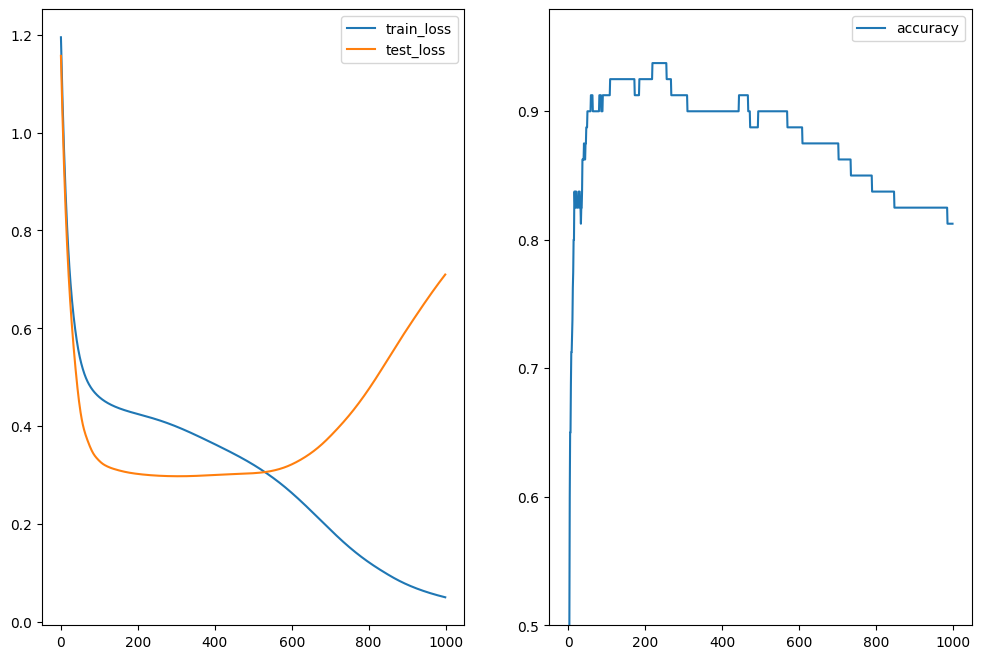

In [30]:
import matplotlib.pyplot as plt

f, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,8))

df_epochs_data[['train_loss', 'test_loss']].plot(ax=ax1)
df_epochs_data[['accuracy']].plot(ax=ax2)

plt.ylim(bottom=0.5)
plt.show()